# Frequency analysis - Array Horizontal
1/3 octave bands
A check at each octave band of the direction of arrival accuracy of each method

How does accuracy vary with frequency

Using butterworth filters to separate recorded signals into 1/3 octave bands

No need to check accuracy at every angle here as the output should be the same no matter the angle, the array in relation to the source should always be symmetric.

This analysis should help us to determine at what frequencies these methods are viable


This Gives opposite results to ITD on the human head. With the head ITD is more accurate for lower frequencies, whereas here, the array is proving to be unreliable below 800Hz. Could be due to the aperatures of each mic, the human head is bigger? Lots to discuss here.

In [10]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
from scipy.signal import butter, lfilter, freqz, sosfreqz, sosfiltfilt
import matplotlib.cm as cm

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code") 

from HATS_functions import gcc_phat, corr_to_itd, xcorr_itd_plain

angles = ["0", "45", "90", "135", "180", "225", "270", "315"]
PathToFiles = "../Audio_Files/Mic_Array/Horizontal"

num_mics = 7
angle_increment = 360/num_mics
fs = 48000

recordings = {}

for angle in angles:
    folder = Path(PathToFiles) / str(angle)
    if folder.is_dir():
        recordings[angle] = {
                '0': folder / "Untitled 1-270.wav",
                '1': folder / "Untitled 2-Audio.wav",
                '2': folder / "Untitled 3-Audio.wav",
                '3': folder / "Untitled 4-Audio.wav",
                '4': folder / "Untitled 5-Audio.wav",
                '5': folder / "Untitled 6-Audio.wav",
                '6': folder / "Untitled 7-Audio.wav",
                '7': folder / "Untitled 8-Audio.wav"
            }
    else:
        print(f"Missing folder: {folder}")

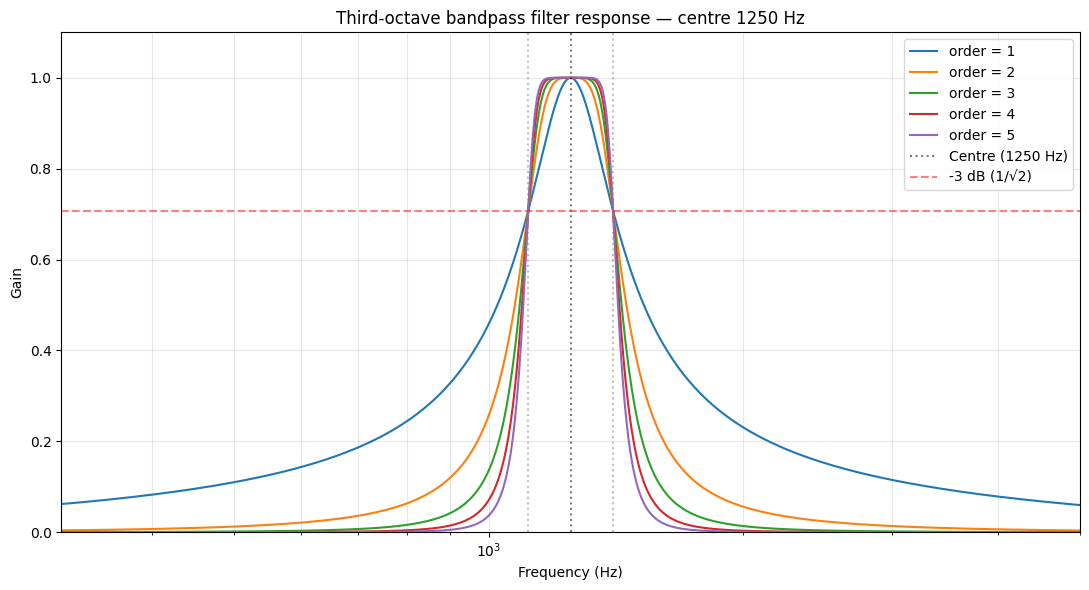

In [11]:
third_octave_centres = [
    125, 160,
    200, 250, 315,
    400, 500, 630,
    800, 1000, 1250,
    1600, 2000, 2500,
    3150, 4000, 5000,
    6300, 8000, 10000,
    12500, 16000
]

def butter_bandpass_sos(lowcut, highcut, fs, order=4):
    sos = butter(order, [lowcut, highcut], btype='band', fs=fs, output='sos')
    return sos

def bandpass_third_octave(signal, fc, fs, order=2):
    low = fc / (2**(1/6))
    high = fc * (2**(1/6))
    high = min(high, fs/2 - 1)
    sos = butter(order, [low, high], btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, signal, axis=0)


fs = 48000.0
fcentre = 1250
lowcut = fcentre / 2**(1/6)
highcut = fcentre * 2**(1/6)

plt.figure(figsize=(11, 6))
for order in [1, 2, 3, 4, 5]:
    sos = butter_bandpass_sos(lowcut, highcut, fs, order=order)
    w, h = sosfreqz(sos, fs=fs, worN=4000)
    plt.semilogx(w, np.abs(h), label=f"order = {order}")

plt.axvline(fcentre, color='k', linestyle=':', alpha=0.5, label=f'Centre ({fcentre} Hz)')
plt.axvline(lowcut, color='gray', linestyle=':', alpha=0.5)
plt.axvline(highcut, color='gray', linestyle=':', alpha=0.5)
plt.axhline(1/np.sqrt(2), color='r', linestyle='--', alpha=0.5, label='-3 dB (1/√2)')

plt.xlabel('Frequency (Hz)')
plt.ylabel('Gain')
plt.title(f'Third-octave bandpass filter response — centre {fcentre} Hz')
plt.grid(True, which='both', alpha=0.3)
plt.legend(loc='best')
plt.xlim(fcentre/4, fcentre*4)
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

Unfiltered correlation:  [ 1.76200120e-04  8.27467324e-06 -1.06296004e-05 ...  5.38807811e-05
 -8.40550521e-06 -1.32548169e-04]
Unfiltered TDOA:  8.333333333333333e-05
Filtered TDOA:  6.25e-05
Unfiltered correlation:  [ 3.03859581e-04 -2.05936291e-04  1.01010790e-04 ...  1.08393526e-04
  3.26089945e-04 -8.66540344e-05]
Unfiltered TDOA:  0.000125
Filtered TDOA:  8.333333333333333e-05
Unfiltered correlation:  [-9.12330077e-05  7.90827298e-05 -1.00241918e-05 ...  9.36606414e-05
 -1.78383857e-05 -3.54929767e-06]
Unfiltered TDOA:  4.1666666666666665e-05
Filtered TDOA:  4.1666666666666665e-05
Unfiltered correlation:  [ 1.27571486e-04 -1.13958614e-04 -2.61183433e-05 ... -1.95553290e-04
  2.61717925e-04 -4.59747524e-04]
Unfiltered TDOA:  -8.333333333333333e-05
Filtered TDOA:  -2.0833333333333333e-05
Unfiltered correlation:  [-1.74593383e-04  8.67289987e-05  6.38727405e-05 ...  2.36513596e-04
 -3.73649780e-04  2.20402701e-04]
Unfiltered TDOA:  -0.000125
Filtered TDOA:  -6.25e-05
Unfiltered corr

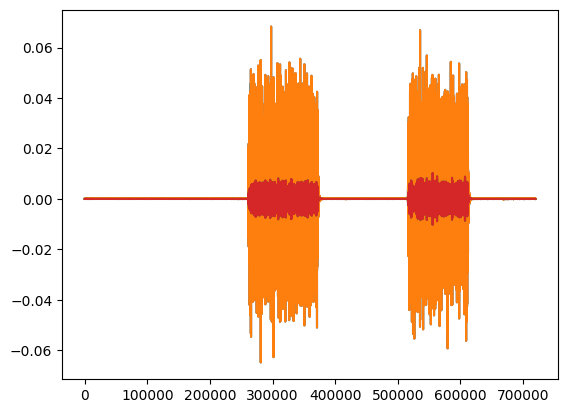

In [12]:
r = 0.045
x = 2 * r * np.sin(np.radians(30))
y = 2 * r * np.sin(np.radians(60))
z = 2 * r * np.sin(np.radians(90))

dists = [[0, r, r, r, r, r, r],
         [r, 0, x, y, z, y, x],
         [r, x, 0, x, y, z, y],
         [r, y, x, 0, x, y, z],
         [r, z, y, x, 0, x, y],
         [r, y, z, y, x, 0, x],
         [r, x, y, z, y, x, 0],]

scores = {'0': 0,
          '1': 0,
          '2': 0,
          '3': 0,
          '4': 0,
          '5': 0,
          '6': 0,}

magnitude = {'0': 0,
          '1': 0,
          '2': 0,
          '3': 0,
          '4': 0,
          '5': 0,
          '6': 0,}

fcentre = 1250
lowcut = fcentre / 2**(1/6)
highcut = fcentre * 2**(1/6)

for i in range(0, 7):
    first = i
    datax, fs = sf.read(recordings['45'][str(i)])
    
    datax_filt = bandpass_third_octave(datax, fcentre, fs)
    
    
    for j in range(i+1, 7):
        second = j
        
        datay, fs = sf.read(recordings['45'][str(j)])
        
        datay_filt = bandpass_third_octave(datay, fcentre, fs)
        
        correlation = gcc_phat(datax, datay)
        itd = corr_to_itd(correlation, dists[i][j], fs)
        print("Unfiltered correlation: ", correlation)
        print("Unfiltered TDOA: ", itd)
        
        itd_filt = xcorr_itd_plain(datax_filt, datay_filt, dists[i][j], fs)
        print("Filtered TDOA: ", itd_filt)
        
        if(itd < 0):
            scores[str(i)] += 1
        else:
            scores[str(j)] += 1
        
          
          
plt.plot(datax)

plt.plot(datax_filt)
        
print(scores)    

In [13]:
import numpy as np
print(f"Unfiltered RMS: {np.sqrt(np.mean(datax**2)):.6f}")
print(f"Filtered RMS:   {np.sqrt(np.mean(datax_filt**2)):.6f}")

Unfiltered RMS: 0.008028
Filtered RMS:   0.001297


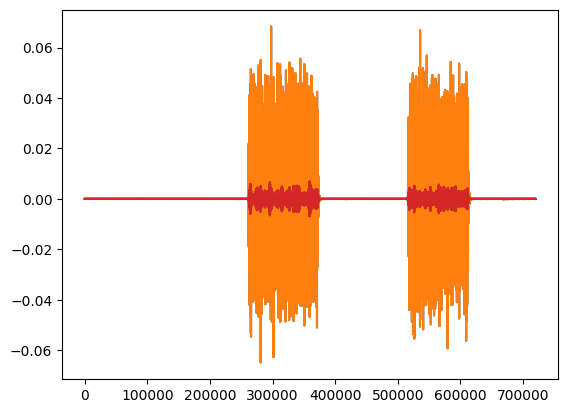

In [14]:
datax, fs = sf.read(recordings['45'][str(i)])
    
datax_filt = bandpass_third_octave(datax, 125, fs)

plt.plot(datax)
plt.plot(datax_filt)

In [15]:
print(datax.shape, datax.ndim)

(719873, 2) 2


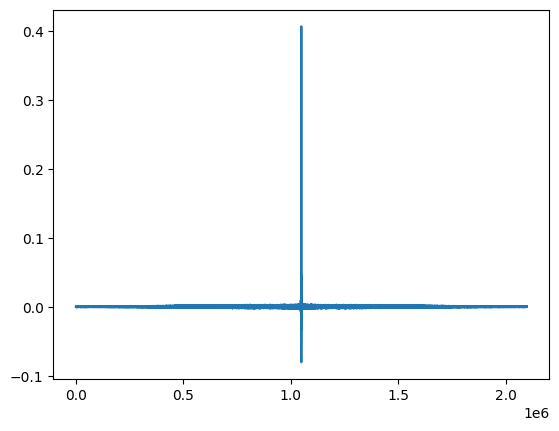

In [16]:
plt.plot(correlation)

In [17]:
r = 0.045
x = 2 * r * np.sin(np.radians(30))
y = 2 * r * np.sin(np.radians(60))
z = 2 * r * np.sin(np.radians(90))

dists = [[0, r, r, r, r, r, r],
         [r, 0, x, y, z, y, x],
         [r, x, 0, x, y, z, y],
         [r, y, x, 0, x, y, z],
         [r, z, y, x, 0, x, y],
         [r, y, z, y, x, 0, x],
         [r, x, y, z, y, x, 0],]

scores = {'0': 0,
          '1': 0,
          '2': 0,
          '3': 0,
          '4': 0,
          '5': 0,
          '6': 0,}

magnitude = {'0': 0,
          '1': 0,
          '2': 0,
          '3': 0,
          '4': 0,
          '5': 0,
          '6': 0,}


results = []

for band in third_octave_centres:
    fcentre = band
    lowcut = fcentre / 2**(1/6)
    highcut = fcentre * 2**(1/6)
    
    scores = {str(i): 0 for i in range(7)}
    
    for i in range(7):
        datax, fs = sf.read(recordings['0'][str(i)])
        if datax.ndim > 1:
            datax = datax.mean(axis=1)
        datax_filt = bandpass_third_octave(datax, fcentre, fs)
        
        for j in range(i + 1, 7):
            datay, _ = sf.read(recordings['0'][str(j)])
            if datay.ndim > 1:
                datay = datay.mean(axis=1)
            datay_filt = bandpass_third_octave(datay, fcentre, fs)
            
            
            itd_filt = xcorr_itd_plain(datax_filt, datay_filt, dists[i][j], fs)
            
            if itd_filt < 0:
                scores[str(i)] += 1
                winner = i
            else:
                scores[str(j)] += 1
                winner = j
            
            results.append({
                'band_hz': band,
                'mic_i': i,
                'mic_j': j,
                'itd_us': itd_filt * 1e6,
                'winner': winner,
            })
    
    results.append({
        'band_hz': band,
        'summary': 'scores',
        **{f'mic_{k}_votes': v for k, v in scores.items()}
    })

df = pd.DataFrame(results)
df.to_csv('freq_analysis_HORIZONTAL_0deg.csv', index=False)

scores_only = df[df['summary'] == 'scores'].drop(columns=['mic_i', 'mic_j', 'itd_us', 'winner', 'summary'])
print(scores_only.to_string(index=False)) 

 band_hz  mic_0_votes  mic_1_votes  mic_2_votes  mic_3_votes  mic_4_votes  mic_5_votes  mic_6_votes
     125          3.0          6.0          4.0          1.0          0.0          2.0          5.0
     160          3.0          6.0          4.0          1.0          0.0          2.0          5.0
     200          3.0          6.0          5.0          2.0          0.0          1.0          4.0
     250          2.0          6.0          5.0          3.0          0.0          1.0          4.0
     315          3.0          6.0          4.0          1.0          0.0          2.0          5.0
     400          2.0          6.0          5.0          3.0          0.0          1.0          4.0
     500          2.0          6.0          5.0          3.0          0.0          1.0          4.0
     630          2.0          6.0          5.0          3.0          0.0          1.0          4.0
     800          3.0          6.0          5.0          2.0          0.0          1.0          4.0


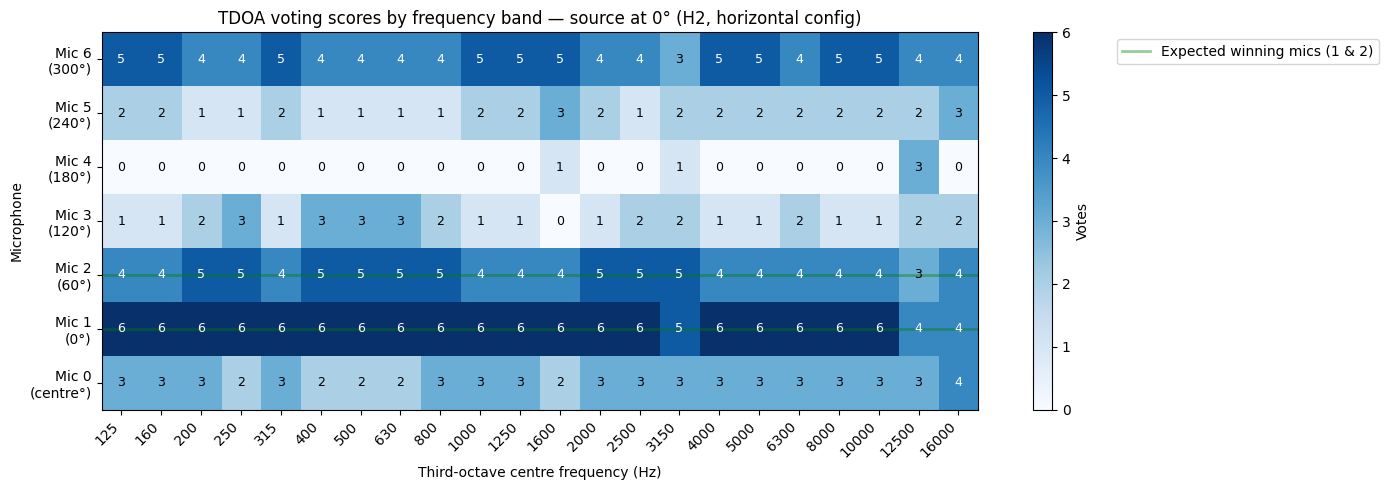

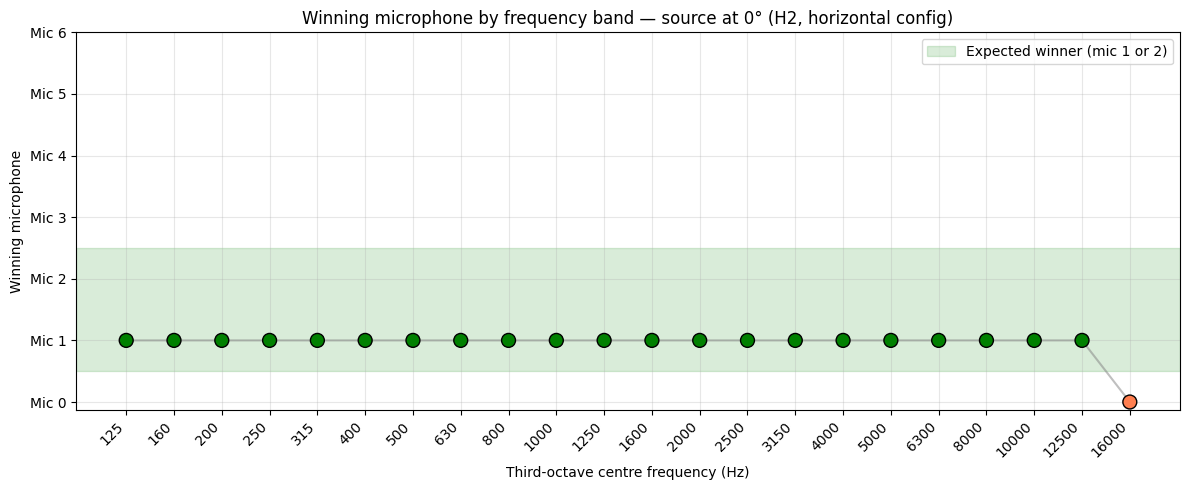

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

df = pd.read_csv('freq_analysis_HORIZONTAL_0deg.csv')
scores_df = df[df['summary'] == 'scores'].copy()

bands = scores_df['band_hz'].values
mic_labels = [f'Mic {k}\n({[0, 60, 120, 180, 240, 300][k-1] if k > 0 else "centre"}°)' 
              for k in range(7)]
vote_matrix = scores_df[[f'mic_{k}_votes' for k in range(7)]].values.T 

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


# Heatmap

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(vote_matrix, cmap='Blues', aspect='auto', origin='lower', vmin=0, vmax=6)

ax.set_xticks(range(len(bands)))
ax.set_xticklabels([f'{int(b)}' for b in bands], rotation=45, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels(mic_labels)
ax.set_xlabel('Third-octave centre frequency (Hz)')
ax.set_ylabel('Microphone')
ax.set_title('TDOA voting scores by frequency band — source at 0° (H2, horizontal config)')

for i in range(7):
    for j in range(len(bands)):
        val = int(vote_matrix[i, j])
        ax.text(j, i, str(val), ha='center', va='center', fontsize=9,
                color='white' if val >= 4 else 'black')

ax.axhline(1, color='green', linewidth=2, alpha=0.4)
ax.axhline(2, color='green', linewidth=2, alpha=0.4, label='Expected winning mics (1 & 2)')

cbar = fig.colorbar(im, ax=ax, ticks=range(7))
cbar.set_label('Votes')

ax.legend(loc='upper left', bbox_to_anchor=(1.15, 1.0))
plt.tight_layout()
#fig.savefig(figures_dir / 'freq_band_voting_heatmap_0deg.png', dpi=200, bbox_inches='tight')
#fig.savefig(figures_dir / 'freq_band_voting_heatmap_0deg.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)

# Line Plot

winners = np.argmax(vote_matrix, axis=0)
correct = (winners == 2) | (winners == 1)  # true source is between mics 1 & 2

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['green' if c else 'coral' for c in correct]
ax.scatter(range(len(bands)), winners, c=colors, s=100, edgecolors='black', zorder=3)
ax.plot(range(len(bands)), winners, color='gray', alpha=0.5, zorder=2)

ax.axhspan(0.5, 2.5, alpha=0.15, color='green', label='Expected winner (mic 1 or 2)')

ax.set_xticks(range(len(bands)))
ax.set_xticklabels([f'{int(b)}' for b in bands], rotation=45, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels([f'Mic {k}' for k in range(7)])
ax.set_xlabel('Third-octave centre frequency (Hz)')
ax.set_ylabel('Winning microphone')
ax.set_title('Winning microphone by frequency band — source at 0° (H2, horizontal config)')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
#fig.savefig(figures_dir / 'freq_band_winner_0deg.png', dpi=200, bbox_inches='tight')
#fig.savefig(figures_dir / 'freq_band_winner_0deg.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)

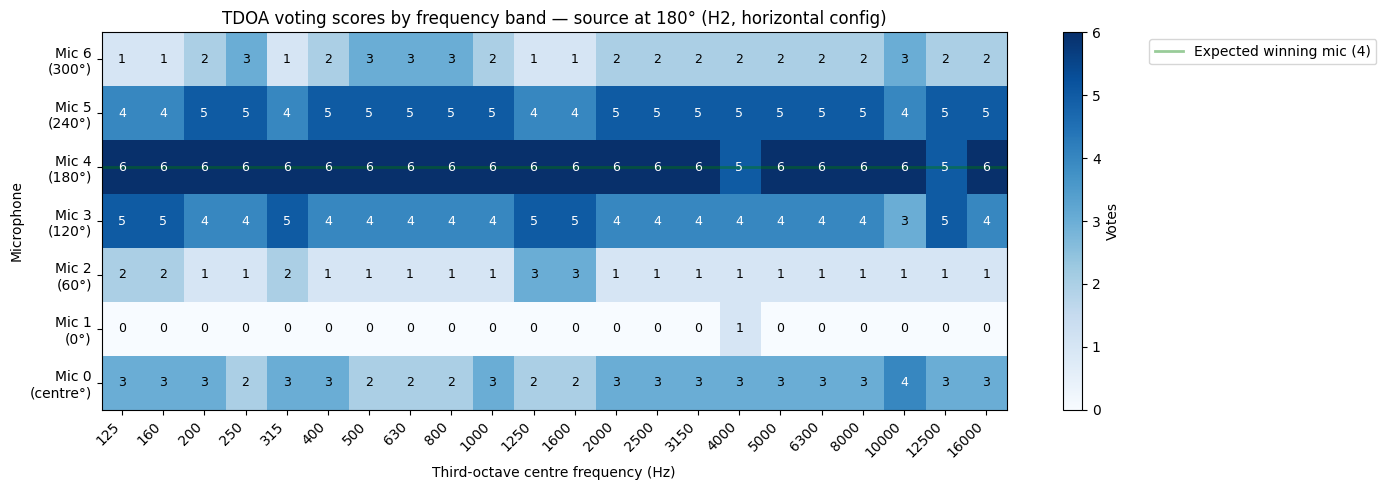

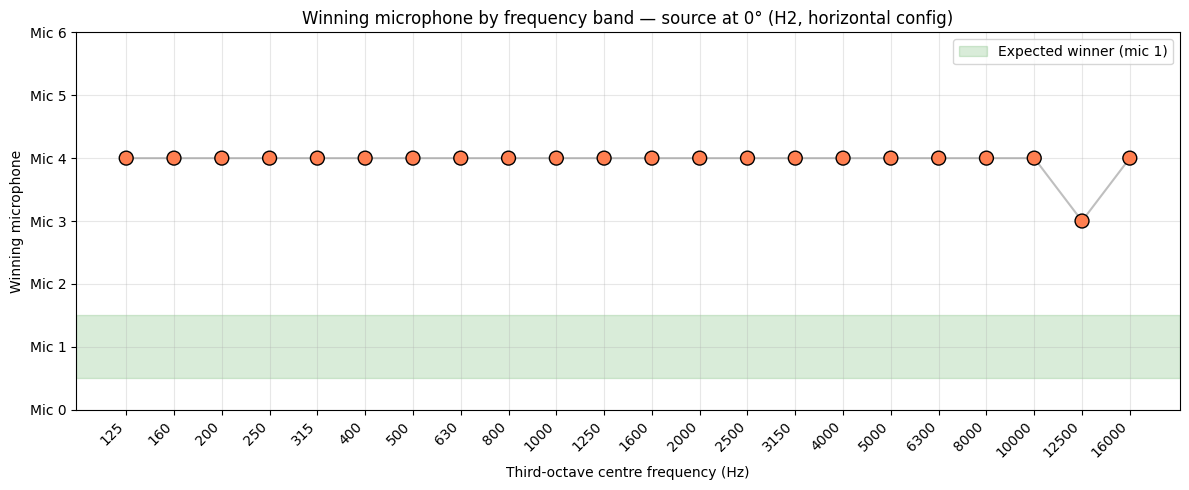

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

df = pd.read_csv('freq_analysis_HORIZONTAL_180deg.csv')
scores_df = df[df['summary'] == 'scores'].copy()

bands = scores_df['band_hz'].values
mic_labels = [f'Mic {k}\n({[0, 60, 120, 180, 240, 300][k-1] if k > 0 else "centre"}°)' 
              for k in range(7)]
vote_matrix = scores_df[[f'mic_{k}_votes' for k in range(7)]].values.T  # (7, n_bands)

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


#Heatmap

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(vote_matrix, cmap='Blues', aspect='auto', origin='lower', vmin=0, vmax=6)

ax.set_xticks(range(len(bands)))
ax.set_xticklabels([f'{int(b)}' for b in bands], rotation=45, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels(mic_labels)
ax.set_xlabel('Third-octave centre frequency (Hz)')
ax.set_ylabel('Microphone')
ax.set_title('TDOA voting scores by frequency band — source at 180° (H2, horizontal config)')


for i in range(7):
    for j in range(len(bands)):
        val = int(vote_matrix[i, j])
        ax.text(j, i, str(val), ha='center', va='center', fontsize=9,
                color='white' if val >= 4 else 'black')



ax.axhline(4, color='green', linewidth=2, alpha=0.4, label='Expected winning mic (4)')

cbar = fig.colorbar(im, ax=ax, ticks=range(7))
cbar.set_label('Votes')

ax.legend(loc='upper left', bbox_to_anchor=(1.15, 1.0))
plt.tight_layout()
#fig.savefig(figures_dir / 'freq_band_voting_heatmap_45deg.png', dpi=200, bbox_inches='tight')
#fig.savefig(figures_dir / 'freq_band_voting_heatmap_45deg.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)


# Line Plot

winners = np.argmax(vote_matrix, axis=0)
correct =  (winners == 1)  # true source is at mic 1

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['green' if c else 'coral' for c in correct]
ax.scatter(range(len(bands)), winners, c=colors, s=100, edgecolors='black', zorder=3)
ax.plot(range(len(bands)), winners, color='gray', alpha=0.5, zorder=2)

ax.axhspan(0.5, 1.5, alpha=0.15, color='green', label='Expected winner (mic 1)')

ax.set_xticks(range(len(bands)))
ax.set_xticklabels([f'{int(b)}' for b in bands], rotation=45, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels([f'Mic {k}' for k in range(7)])
ax.set_xlabel('Third-octave centre frequency (Hz)')
ax.set_ylabel('Winning microphone')
ax.set_title('Winning microphone by frequency band — source at 0° (H2, horizontal config)')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
#fig.savefig(figures_dir / 'freq_band_winner_45deg.png', dpi=200, bbox_inches='tight')
#fig.savefig(figures_dir / 'freq_band_winner_45deg.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)